In [8]:
import io
import os
import pandas as pd
import paramiko

import matplotlib.pyplot as plt
df=pd.read_pickle("Sample_Feb.pkl")
ts = pd.to_datetime(df["Timestamp (end of interval)"])

df_speed = df[
    (ts >= "2025-02-12 18:00:00") &
    (ts <= "2025-02-13 06:00:00")
].copy()
speed_cols = [col for col in df_speed.columns if "Wind Speed (m/s)" in col]
keep_cols = ["Timestamp (end of interval)"] + speed_cols

df_speed = df_speed[keep_cols].copy()
df_speed

,Timestamp (end of interval),40m Wind Speed (m/s),60m Wind Speed (m/s),80m Wind Speed (m/s),100m Wind Speed (m/s),120m Wind Speed (m/s),140m Wind Speed (m/s),160m Wind Speed (m/s),180m Wind Speed (m/s),200m Wind Speed (m/s),220m Wind Speed (m/s),240m Wind Speed (m/s),260m Wind Speed (m/s),280m Wind Speed (m/s),300m Wind Speed (m/s)
1677,2025-02-12 18:00:00,1.23,1.25,1.53,1.94,2.65,3.34,3.96,4.46,4.86,5.32,5.86,6.18,6.37,6.66
1678,2025-02-12 18:10:00,2.07,1.87,1.17,1.32,2.02,2.72,3.31,3.79,4.33,4.83,5.33,5.57,5.80,6.08
1679,2025-02-12 18:20:00,1.22,1.59,2.00,2.04,2.68,3.22,3.54,3.84,4.23,4.79,5.16,5.41,5.62,5.90
1680,2025-02-12 18:30:00,0.99,1.38,1.93,2.45,3.03,3.50,3.80,4.02,4.27,4.55,4.76,5.05,5.45,6.36
1681,2025-02-12 18:40:00,0.96,1.05,1.54,2.19,2.75,3.36,4.08,4.54,4.72,4.90,5.07,5.31,5.53,5.64
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1745,2025-02-13 05:20:00,13.65,15.34,16.32,17.04,17.56,18.15,18.46,19.07,19.47,19.97,20.63,21.15,21.78,22.53
1746,2025-02-13 05:30:00,12.70,14.35,15.75,16.72,17.38,17.82,18.32,18.93,19.37,19.79,20.22,20.76,21.38,21.86
1747,2025-02-13 05:40:00,13.74,15.42,16.34,17.19,18.09,18.89,19.72,20.59,21.46,22.33,22.96,23.31,24.03,24.58
1748,2025-02-13 05:50:00,14.49,16.59,17.62,18.30,18.87,19.47,19.96,20.69,21.48,22.03,22.47,22.95,23.38,24.02


In [9]:
import re
# 方向データの列を高度順に並べ、各高度ペアごとの veer を追加
# 例: 40-60m Veer, 60-80m Veer, ...
speed_cols = [col for col in df_deg.columns if "Wind Speed (m/s)" in col]
speed_cols = sorted(speed_cols, key=lambda c: int(re.search(r"(\d+)m", c).group(1)))

for i in range(len(speed_cols) - 1):
    left_col = speed_cols[i]
    right_col = speed_cols[i + 1]
    left_h = re.search(r"(\d+)m", left_col).group(1)
    right_h = re.search(r"(\d+)m", right_col).group(1)

    veer_name = f"{left_h}-{right_h}m DIF"
    diff = df_speed[left_col] - df_speed[right_col]
    df_speed.insert(df_speed.columns.get_loc(left_col) + 1, veer_name, diff)

# 生成結果の確認
df_speed.head()

,Timestamp (end of interval),40m Wind Speed (m/s),40-60m DIF,60m Wind Speed (m/s),60-80m DIF,80m Wind Speed (m/s),80-100m DIF,100m Wind Speed (m/s),100-120m DIF,120m Wind Speed (m/s),...,200-220m DIF,220m Wind Speed (m/s),220-240m DIF,240m Wind Speed (m/s),240-260m DIF,260m Wind Speed (m/s),260-280m DIF,280m Wind Speed (m/s),280-300m DIF,300m Wind Speed (m/s)
1677,2025-02-12 18:00:00,1.23,-0.02,1.25,-0.28,1.53,-0.41,1.94,-0.71,2.65,...,-0.46,5.32,-0.54,5.86,-0.32,6.18,-0.19,6.37,-0.29,6.66
1678,2025-02-12 18:10:00,2.07,0.20,1.87,0.70,1.17,-0.15,1.32,-0.70,2.02,...,-0.50,4.83,-0.50,5.33,-0.24,5.57,-0.23,5.80,-0.28,6.08
1679,2025-02-12 18:20:00,1.22,-0.37,1.59,-0.41,2.00,-0.04,2.04,-0.64,2.68,...,-0.56,4.79,-0.37,5.16,-0.25,5.41,-0.21,5.62,-0.28,5.90
1680,2025-02-12 18:30:00,0.99,-0.39,1.38,-0.55,1.93,-0.52,2.45,-0.58,3.03,...,-0.28,4.55,-0.21,4.76,-0.29,5.05,-0.40,5.45,-0.91,6.36
1681,2025-02-12 18:40:00,0.96,-0.09,1.05,-0.49,1.54,-0.65,2.19,-0.56,2.75,...,-0.18,4.90,-0.17,5.07,-0.24,5.31,-0.22,5.53,-0.11,5.64


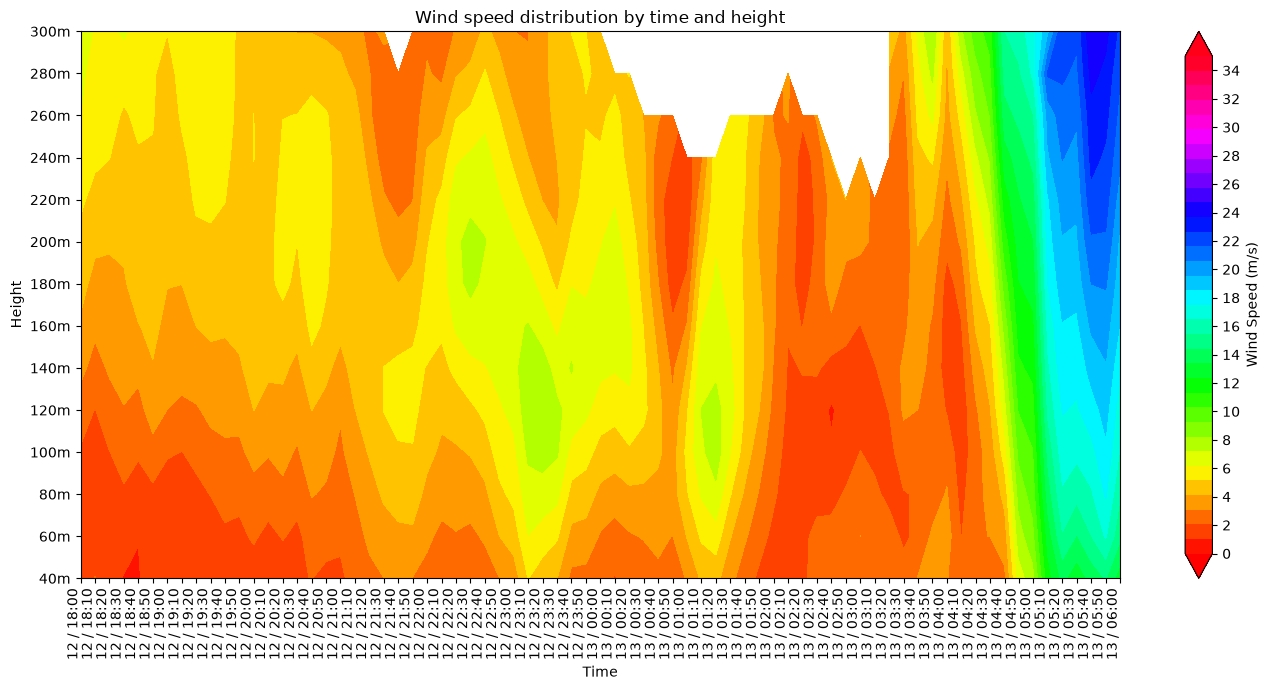

In [30]:
import re
import numpy as np

# 風速の列を高度順に並べる
wind_speed_cols = sorted(
    [c for c in df_speed.columns if "Wind Speed" in c],
    key=lambda c: int(re.search(r"(\d+)m", c).group(1)),
)

# 0–360° の範囲に揃える
wind_speed_df = df_speed.set_index("Timestamp (end of interval)")[wind_speed_cols].copy()


# 縦軸に使う高度（40, 60, 80, ...）
heights = [int(re.search(r"(\d+)m", c).group(1)) for c in wind_speed_cols]

fig, ax = plt.subplots(figsize=(14, 7))
mesh = ax.contourf(
    np.arange(len(wind_speed_df.index)),
    heights,
    wind_speed_df.T.to_numpy(),
    levels=np.linspace(0, 35, 35),
    cmap="hsv",
    extend="both",
)

ax.set_yticks(heights)
ax.set_yticklabels([f"{h}m" for h in heights])
ax.set_xticks(np.arange(len(wind_speed_df.index)))
ax.set_xticklabels(wind_speed_df.index.strftime("%d / %H:%M"), rotation=90, ha="right")
ax.set_xlabel("Time")
ax.set_ylabel("Height")
ax.set_title("Wind speed distribution by time and height")

cbar = fig.colorbar(mesh, ax=ax, label="Wind Speed (m/s)")
cbar.set_ticks(np.arange(0, 35, 2))
plt.tight_layout()
plt.show()


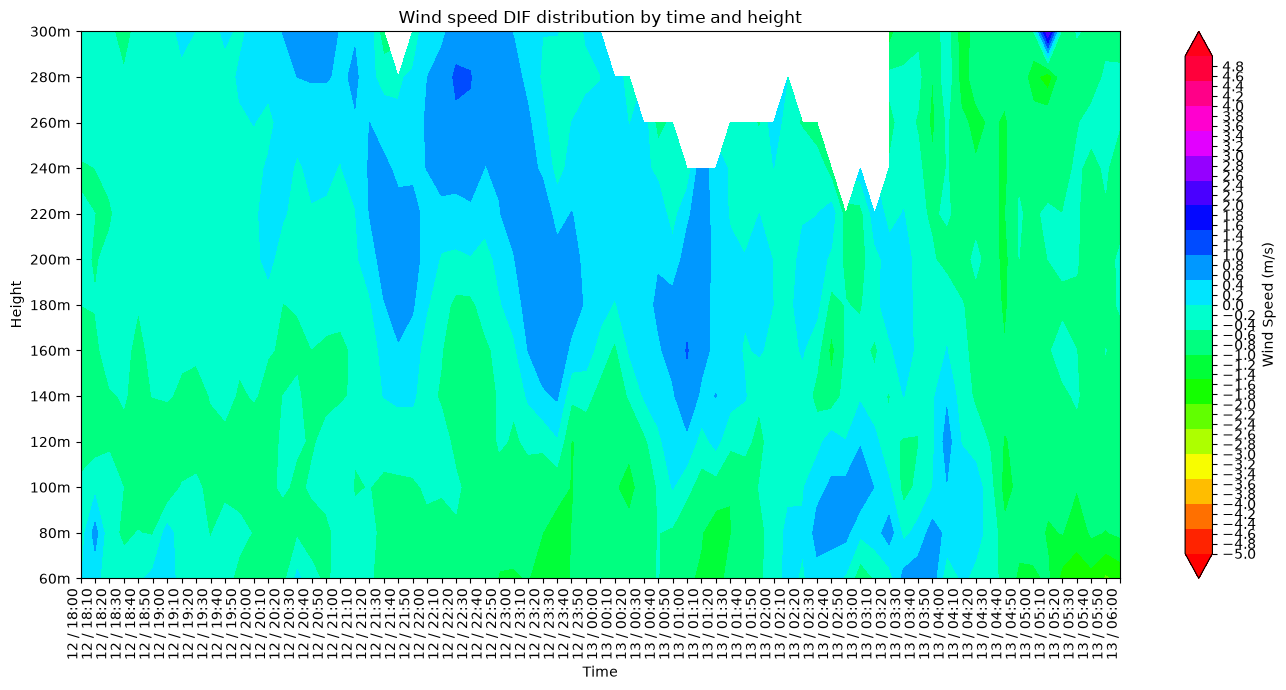

In [31]:
import re
import numpy as np

# 風速の列を高度順に並べる
wind_speed_cols = sorted(
    [c for c in df_speed.columns if "DIF" in c],
    key=lambda c: int(re.search(r"(\d+)m", c).group(1)),
)

# 0–360° の範囲に揃える
wind_speed_df = df_speed.set_index("Timestamp (end of interval)")[wind_speed_cols].copy()


# 縦軸に使う高度（40, 60, 80, ...）
heights = [int(re.search(r"(\d+)m", c).group(1)) for c in wind_speed_cols]

fig, ax = plt.subplots(figsize=(14, 7))
mesh = ax.contourf(
    np.arange(len(wind_speed_df.index)),
    heights,
    wind_speed_df.T.to_numpy(),
    levels=np.linspace(-5, 5, 21),
    cmap="hsv",
    extend="both",
)

ax.set_yticks(heights)
ax.set_yticklabels([f"{h}m" for h in heights])
ax.set_xticks(np.arange(len(wind_speed_df.index)))
ax.set_xticklabels(wind_speed_df.index.strftime("%d / %H:%M"), rotation=90, ha="right")
ax.set_xlabel("Time")
ax.set_ylabel("Height")
ax.set_title("Wind speed DIF distribution by time and height")

cbar = fig.colorbar(mesh, ax=ax, label="Wind Speed (m/s)")
cbar.set_ticks(np.arange(-5, 5, 0.2))
plt.tight_layout()
plt.show()